In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
train_df=pd.read_csv("/content/train.csv")
test_df=pd.read_csv("/content/test.csv")

In [ ]:
train_df.head(10)

,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,0000997932d777bf,Explanation\nWhy the edits made under my usern...,0,0,0,0,0,0
1,000103f0d9cfb60f,D'aww! He matches this background colour I'm s...,0,0,0,0,0,0
2,000113f07ec002fd,"Hey man, I'm really not trying to edit war. It...",0,0,0,0,0,0
3,0001b41b1c6bb37e,"""\nMore\nI can't make any real suggestions on ...",0,0,0,0,0,0
4,0001d958c54c6e35,"You, sir, are my hero. Any chance you remember...",0,0,0,0,0,0
5,00025465d4725e87,"""\n\nCongratulations from me as well, use the ...",0,0,0,0,0,0
6,0002bcb3da6cb337,COCKSUCKER BEFORE YOU PISS AROUND ON MY WORK,1,1,1,0,1,0
7,00031b1e95af7921,Your vandalism to the Matt Shirvington article...,0,0,0,0,0,0
8,00037261f536c51d,Sorry if the word 'nonsense' was offensive to ...,0,0,0,0,0,0
9,00040093b2687caa,alignment on this subject and which are contra...,0,0,0,0,0,0


In [ ]:
test_df.head(10)

,id,comment_text
0,00001cee341fdb12,Yo bitch Ja Rule is more succesful then you'll...
1,0000247867823ef7,== From RfC == \n\n The title is fine as it is...
2,00013b17ad220c46,""" \n\n == Sources == \n\n * Zawe Ashton on Lap..."
3,00017563c3f7919a,":If you have a look back at the source, the in..."
4,00017695ad8997eb,I don't anonymously edit articles at all.
5,0001ea8717f6de06,Thank you for understanding. I think very high...
6,00024115d4cbde0f,Please do not add nonsense to Wikipedia. Such ...
7,000247e83dcc1211,:Dear god this site is horrible.
8,00025358d4737918,""" \n Only a fool can believe in such numbers. ..."
9,00026d1092fe71cc,== Double Redirects == \n\n When fixing double...


In [ ]:
train_df.shape

(159571, 8)

In [ ]:
test_df.shape

(153164, 2)

In [ ]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 159571 entries, 0 to 159570
Data columns (total 8 columns):
 #   Column         Non-Null Count   Dtype 
---  ------         --------------   ----- 
 0   id             159571 non-null  object
 1   comment_text   159571 non-null  object
 2   toxic          159571 non-null  int64 
 3   severe_toxic   159571 non-null  int64 
 4   obscene        159571 non-null  int64 
 5   threat         159571 non-null  int64 
 6   insult         159571 non-null  int64 
 7   identity_hate  159571 non-null  int64 
dtypes: int64(6), object(2)
memory usage: 9.7+ MB


In [ ]:
test_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 153164 entries, 0 to 153163
Data columns (total 2 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   id            153164 non-null  object
 1   comment_text  153164 non-null  object
dtypes: object(2)
memory usage: 2.3+ MB


In [ ]:
#Checking Missing values

test_df.isnull().sum()

,0
id,0
comment_text,0


In [ ]:
train_df.isnull().sum()

,0
id,0
comment_text,0
toxic,0
severe_toxic,0
obscene,0
threat,0
insult,0
identity_hate,0


In [ ]:
#Checking Duplicated Values

train_df.duplicated().sum()

np.int64(0)

In [ ]:
test_df.duplicated().sum()

np.int64(0)

In [ ]:
#Target Label Distribution

target_columns=["toxic","severe_toxic","obscene","threat","insult","identity_hate"]
label_counts=train_df[target_columns].sum()
label_counts

,0
toxic,15294
severe_toxic,1595
obscene,8449
threat,478
insult,7877
identity_hate,1405


In [ ]:
#Label_Percentage

labels_percentage=(train_df[target_columns].mean()*100).round(2)
print(labels_percentage)

toxic            9.58
severe_toxic     1.00
obscene          5.29
threat           0.30
insult           4.94
identity_hate    0.88
dtype: float64


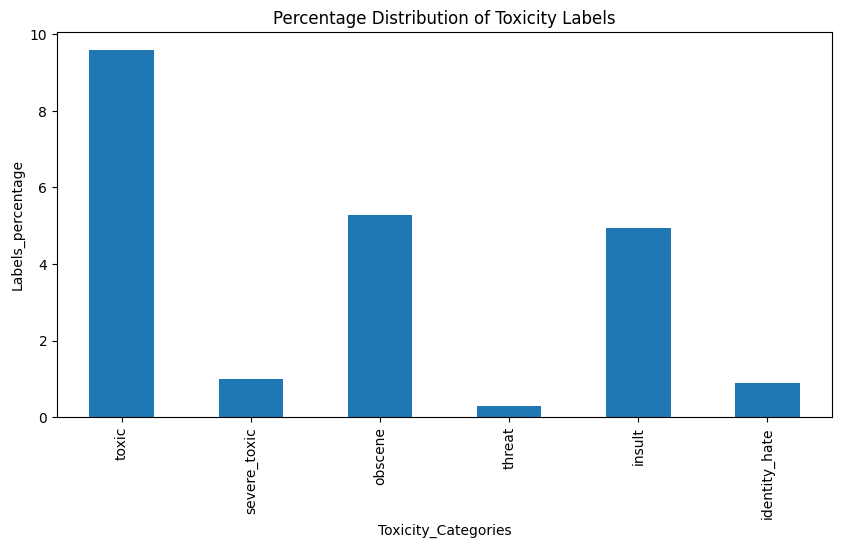

In [ ]:
# Data Visualization
#Bar chart

plt.figure(figsize=(10,5))
labels_percentage.plot(kind="bar")
plt.title("Percentage Distribution of Toxicity Labels")
plt.xlabel("Toxicity_Categories")
plt.ylabel("Labels_percentage")
plt.show()

In [ ]:
#Comment Length Analysis

train_df["comment_length"] = train_df["comment_text"].apply(
    lambda x: len(x.split()))

print(train_df["comment_length"].describe())

count    159571.000000
mean         67.273521
std          99.230703
min           1.000000
25%          17.000000
50%          36.000000
75%          75.000000
max        1411.000000
Name: comment_length, dtype: float64


In [ ]:
#Text Cleaning

train_df["comment_text"].head(20)

,comment_text
0,Explanation\nWhy the edits made under my usern...
1,D'aww! He matches this background colour I'm s...
2,"Hey man, I'm really not trying to edit war. It..."
3,"""\nMore\nI can't make any real suggestions on ..."
4,"You, sir, are my hero. Any chance you remember..."
5,"""\n\nCongratulations from me as well, use the ..."
6,COCKSUCKER BEFORE YOU PISS AROUND ON MY WORK
7,Your vandalism to the Matt Shirvington article...
8,Sorry if the word 'nonsense' was offensive to ...
9,alignment on this subject and which are contra...


In [ ]:
#Checking HTML Tags

import re
html_count = train_df["comment_text"].str.contains(r"<[^>]+>", regex=True, na=False).sum()
print("Comments containing HTML tags:", html_count)

Comments containing HTML tags: 84


In [ ]:
#Checking URLs

url_count=url_count = train_df["comment_text"].str.contains(r"http\S+|www\S+", regex=True, na=False).sum()
print("Comments containing URLs:", url_count)

Comments containing URLs: 5151


In [ ]:
#Checking Newline characters exist

newline_count = train_df["comment_text"].str.contains(r"\n", regex=True, na=False).sum()
print("Comments containing newlines:", newline_count)

Comments containing newlines: 94466


In [ ]:
#Checking special characters

special_chars = train_df["comment_text"].str.findall(r"[^a-zA-Z0-9\s]").explode().value_counts()
print(special_chars.head(30))

comment_text
.    680368
,    474958
"    392552
'    219429
!    105576
-    102382
:     95215
)     90711
(     85085
?     71692
/     58994
=     31010
;     21899
_     19087
|     14406
]      8876
[      8301
~      7770
&      6735
—      6450
{      6426
#      6232
}      6082
•      5890
%      5702
*      5275
’      3854
+      3301
–      2774
“      2301
Name: count, dtype: int64


In [ ]:
url_comments = train_df[
    train_df["comment_text"].str.contains(
        r"http\S+|www\S+", regex=True, na=False
    )
]

print(url_comments["comment_text"].head(10).to_string(index=False))

"\n\n Snowflakes are NOT always symmetrical! \n...
I was able to post the above list so quickly be...
"\n Ambiguous ? \nSo Mabuska Irish can mean mor...
Transliteration of Russian place names\nIn writ...
Check the following websites:\n\nhttp://www.ira...
Also see this if you cant trust Murkoth Ramunni...
Should say something about his views as an educ...
George W. Bush approval rating graph \n\nhttp:/...
And check this out: http://www.cla.purdue.edu/b...
http://www.users.bigpond.com/MONTDALE/page8.htm...


In [ ]:
html_comments = train_df[
    train_df["comment_text"].str.contains(
        r"<[^>]+>", regex=True, na=False
    )
]

print(html_comments["comment_text"].head(10).to_string(index=False))

Don't vandalize other wikipedians pages. 2nd wa...
1)I am an admin, so I guess you were only re-st...
"\n\n ""Lolita Midsleeper Combi""  furniture,  ...
Hi.\n\n Re: ɰ\n /ɰ/ is equivalent to what some ...
" NawlinWiki  WHY DID YOU DELETE THE PAGE ABOUT...
Seems discussion proves convincingly that <<......
"\n\n Happy New Year 2006 \nA year has only 365...
Hello Gwickwire,\n\nThank you for your helpful ...
"\n\n Questions about a certain [reversion] edi...
Ah, ok, looked some stuff up. So r can be negat...


In [ ]:
markdown_count = train_df["comment_text"].str.contains(
    r"\[.*?\]\(.*?\)", regex=True, na=False
).sum()

print("Comments containing Markdown links:", markdown_count)

Comments containing Markdown links: 3


In [ ]:
import re

def clean_text(text):
    # Remove Markdown links but keep their display text
    text = re.sub(r"\[([^\]]+)\]\([^)]+\)", r"\1", text)

    # Remove URLs
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)

    # Remove actual HTML tags
    text = re.sub(
        r"</?[A-Za-z][A-Za-z0-9]*(?:\s+[^<>]*)?\s*/?>",
        " ",
        text
    )

    # Replace HTML space entities
    text = re.sub(r"&#x20;|&nbsp;", " ", text, flags=re.IGNORECASE)

    # Replace newlines and extra whitespace
    text = re.sub(r"\s+", " ", text)
    return text.strip()

In [ ]:
train_df["cleaned_text"] = train_df["comment_text"].apply(clean_text)
test_df["cleaned_text"] = test_df["comment_text"].apply(clean_text)

In [ ]:
train_df[["comment_text", "cleaned_text"]].head()

,comment_text,cleaned_text
0,Explanation\nWhy the edits made under my usern...,Explanation Why the edits made under my userna...
1,D'aww! He matches this background colour I'm s...,D'aww! He matches this background colour I'm s...
2,"Hey man, I'm really not trying to edit war. It...","Hey man, I'm really not trying to edit war. It..."
3,"""\nMore\nI can't make any real suggestions on ...",""" More I can't make any real suggestions on im..."
4,"You, sir, are my hero. Any chance you remember...","You, sir, are my hero. Any chance you remember..."


In [ ]:
print("Empty training comments:",
      (train_df["cleaned_text"].str.strip() == "").sum())

print("Empty test comments:",
      (test_df["cleaned_text"].str.strip() == "").sum())

Empty training comments: 7
Empty test comments: 5


In [ ]:
empty_train = train_df[
    train_df["cleaned_text"].str.strip() == ""
]

print(empty_train["comment_text"].to_string(index=False))

http://en.wikipedia.org/wiki/Wikipedia_talk:No_...
http://finance.yahoo.com/news/7-fascinating-nug...
http://wikipediawehaveaproblem.com/evidence-of-...
      http://en.wikipedia.org/wiki/Wikipedia:ELYES
http://www.mediamonitors.net/edna47.html   http...
http://www.haaretz.com/news/diplomacy-defense/2...
http://www.world-pyramids.com/atr/usa/monkmound...


In [ ]:
train_df = train_df[
    train_df["cleaned_text"].str.strip() != ""
].copy()

print(train_df.shape)

(159564, 10)


In [ ]:
#Train Test Split

from sklearn.model_selection import train_test_split

target_columns = [
    "toxic",
    "severe_toxic",
    "obscene",
    "threat",
    "insult",
    "identity_hate"
]

X = train_df["cleaned_text"]
y = train_df[target_columns]

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))

Training samples: 127651
Validation samples: 31913


In [ ]:
# Tokenization

# Step 1: Import Tokenizer
from tensorflow.keras.preprocessing.text import Tokenizer

# Step 2: Create the tokenizer
tokenizer = Tokenizer(
    num_words=20000,
    oov_token="<OOV>"
)

# Step 3: Fit tokenizer using training text only
tokenizer.fit_on_texts(X_train)

# Step 4: Convert training comments into numerical sequences
X_train_sequences = tokenizer.texts_to_sequences(X_train)

# Step 5: Convert validation comments into numerical sequences
X_val_sequences = tokenizer.texts_to_sequences(X_val)

# Step 6: Convert test comments into numerical sequences
X_test_sequences = tokenizer.texts_to_sequences(test_df["cleaned_text"])

In [ ]:
# Check vocabulary size
print("Total unique words:", len(tokenizer.word_index))

# Display first 20 word-number mappings
print("\nFirst 20 words:")
print(list(tokenizer.word_index.items())[:20])

# Display original comment
print("\nOriginal comment:")
print(X_train.iloc[0])

# Display numerical sequence
print("\nNumerical sequence:")
print(X_train_sequences[0])

Total unique words: 174954

First 20 words:
[('<OOV>', 1), ('the', 2), ('to', 3), ('and', 4), ('of', 5), ('a', 6), ('you', 7), ('i', 8), ('is', 9), ('that', 10), ('in', 11), ('it', 12), ('for', 13), ('this', 14), ('not', 15), ('on', 16), ('be', 17), ('as', 18), ('have', 19), ('are', 20)]

Original comment:
EDITING/DELETING Hi, im user:CJ2005B. I dont go round trying to make enemys with anyone! all i asked is that you and other wikipedia users be fair. so far you have not been! all i ask is that be fair when editing/deleting my post. thanks you

Numerical sequence:
[123, 622, 160, 780, 95, 1, 8, 442, 122, 2179, 249, 3, 98, 1, 22, 258, 43, 8, 596, 9, 10, 7, 4, 62, 31, 345, 17, 270, 38, 314, 7, 19, 15, 56, 43, 8, 212, 9, 10, 17, 270, 81, 123, 622, 29, 310, 94, 7]


In [ ]:
sequence_lengths = [len(seq) for seq in X_train_sequences]

print(pd.Series(sequence_lengths).describe())

count    127651.000000
mean         67.747570
std         100.718984
min           0.000000
25%          17.000000
50%          36.000000
75%          76.000000
max        1403.000000
dtype: float64


In [ ]:
import numpy as np

print("90th percentile:", np.percentile(sequence_lengths, 90))
print("95th percentile:", np.percentile(sequence_lengths, 95))
print("99th percentile:", np.percentile(sequence_lengths, 99))

90th percentile: 153.0
95th percentile: 230.0
99th percentile: 576.0


In [ ]:
#Padding and Truncation

from tensorflow.keras.preprocessing.sequence import pad_sequences
# Maximum sequence length
max_len = 230

# Padding training sequences
X_train_padded = pad_sequences(
    X_train_sequences,
    maxlen=max_len,
    padding="post",
    truncating="post"
)

# Padding validation sequences
X_val_padded = pad_sequences(
    X_val_sequences,
    maxlen=max_len,
    padding="post",
    truncating="post"
)

# Padding test sequences
X_test_padded = pad_sequences(
    X_test_sequences,
    maxlen=max_len,
    padding="post",
    truncating="post"
)

In [ ]:
print("Training shape:", X_train_padded.shape)
print("Validation shape:", X_val_padded.shape)
print("Test shape:", X_test_padded.shape)

Training shape: (127651, 230)
Validation shape: (31913, 230)
Test shape: (153164, 230)


In [ ]:
print("Original sequence:")
print(X_train_sequences[0])

print("\nPadded sequence:")
print(X_train_padded[0])

print("\nPadded sequence length:")
print(len(X_train_padded[0]))

Original sequence:
[123, 622, 160, 780, 95, 1, 8, 442, 122, 2179, 249, 3, 98, 1, 22, 258, 43, 8, 596, 9, 10, 7, 4, 62, 31, 345, 17, 270, 38, 314, 7, 19, 15, 56, 43, 8, 212, 9, 10, 17, 270, 81, 123, 622, 29, 310, 94, 7]

Padded sequence:
[ 123  622  160  780   95    1    8  442  122 2179  249    3   98    1
   22  258   43    8  596    9   10    7    4   62   31  345   17  270
   38  314    7   19   15   56   43    8  212    9   10   17  270   81
  123  622   29  310   94    7    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0   

In [ ]:
#Preparing Target Labels

target_columns = [
    "toxic",
    "severe_toxic",
    "obscene",
    "threat",
    "insult",
    "identity_hate"
]

In [ ]:
y = train_df[target_columns] #separating target columns
y_train_array = y_train.values
y_val_array = y_val.values

In [ ]:
print("Training labels shape:", y_train_array.shape)
print("Validation labels shape:", y_val_array.shape)

Training labels shape: (127651, 6)
Validation labels shape: (31913, 6)


In [ ]:
print("First 5 training labels:")
print(y_train_array[:30])

First 5 training labels:
[[0 0 0 0 0 0]
 [0 0 0 0 0 0]
 [0 0 0 0 0 0]
 [0 0 0 0 0 0]
 [0 0 0 0 0 0]
 [0 0 0 0 0 0]
 [0 0 0 0 0 0]
 [0 0 0 0 0 0]
 [0 0 0 0 0 0]
 [0 0 0 0 0 0]
 [0 0 0 0 0 0]
 [0 0 0 0 0 0]
 [0 0 0 0 0 0]
 [0 0 0 0 0 0]
 [0 0 0 0 0 0]
 [0 0 0 0 0 0]
 [0 0 0 0 0 0]
 [0 0 0 0 0 0]
 [0 0 0 0 0 0]
 [0 0 0 0 0 0]
 [0 0 0 0 0 0]
 [1 0 1 0 1 0]
 [0 0 0 0 0 0]
 [0 0 0 0 0 0]
 [0 0 0 0 0 0]
 [0 0 0 0 0 0]
 [1 0 0 0 0 0]
 [0 0 0 0 0 0]
 [0 0 0 0 0 0]
 [0 0 0 0 0 0]]


In [ ]:
for i, label in enumerate(target_columns):
    print(label, ":", y_train_array[:, i].sum())

toxic : 12271
severe_toxic : 1286
obscene : 6777
threat : 377
insult : 6307
identity_hate : 1104


In [ ]:
for i in range(10):

    print("Comment:")
    print(X_train.iloc[i])

    print("\nActual labels:")
    print(y_train.iloc[i].to_dict())

    print("-" * 60)

Comment:
EDITING/DELETING Hi, im user:CJ2005B. I dont go round trying to make enemys with anyone! all i asked is that you and other wikipedia users be fair. so far you have not been! all i ask is that be fair when editing/deleting my post. thanks you

Actual labels:
{'toxic': 0, 'severe_toxic': 0, 'obscene': 0, 'threat': 0, 'insult': 0, 'identity_hate': 0}
------------------------------------------------------------
Comment:
(UTC) It comes from the seventh layer of hell and thats where it should stay, gross! 18:19, 9 September 2006

Actual labels:
{'toxic': 0, 'severe_toxic': 0, 'obscene': 0, 'threat': 0, 'insult': 0, 'identity_hate': 0}
------------------------------------------------------------
Comment:
" FYI Noticed the message ""Access denied for user 'tparis'@'%.toolserver.org' to database 'u_soxred93'"" at the top of the results when I checked my contribs at . The output otherwise seemed fine, just thought I'd mention it. "

Actual labels:
{'toxic': 0, 'severe_toxic': 0, 'obscen

In [ ]:
import numpy as np

print("Total training comments:", len(y_train_array))

print("Comments with at least one toxicity label:",
      np.sum(y_train_array.sum(axis=1) > 0))

print("Comments with no toxicity labels:",
      np.sum(y_train_array.sum(axis=1) == 0))

Total training comments: 127651
Comments with at least one toxicity label: 13022
Comments with no toxicity labels: 114629


In [ ]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("Available GPU:", tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.21.0
Available GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
import numpy as np

for name, data in [
    ("Training", X_train_padded),
    ("Validation", X_val_padded),
    ("Testing", X_test_padded)
]:
    empty_rows = np.sum(np.all(data == 0, axis=1))
    print(name, "empty sequences:", empty_rows)

Training empty sequences: 4
Validation empty sequences: 2
Testing empty sequences: 43


In [ ]:
import numpy as np

for data in [X_train_padded, X_val_padded, X_test_padded]:

    empty_rows = np.all(data == 0, axis=1)

    data[empty_rows, 0] = 1


# Verify the correction

print("Training empty sequences:",
      np.sum(np.all(X_train_padded == 0, axis=1)))

print("Validation empty sequences:",
      np.sum(np.all(X_val_padded == 0, axis=1)))

print("Testing empty sequences:",
      np.sum(np.all(X_test_padded == 0, axis=1)))

Training empty sequences: 0
Validation empty sequences: 0
Testing empty sequences: 0


In [ ]:
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping



In [ ]:
# Model parameters
vocab_size = 20000
embedding_dim = 128
max_len = 230
num_labels = 6

# Build LSTM model
model = Sequential([

    Input(shape=(max_len,)),

    Embedding(
        input_dim=vocab_size,
        output_dim=embedding_dim,
        mask_zero=True
    ),

    LSTM(64),
    Dropout(0.3),
    Dense(64, activation="relu"),
    Dropout(0.3),
    Dense(num_labels, activation="sigmoid")
])

# Compile model
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.AUC(
            name="pr_auc",
            curve="PR",
            multi_label=True
        )
    ]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 230, 128)       │     2,560,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,613,958 (9.97 MB)

 Trainable params: 2,613,958 (9.97 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

history = model.fit(
    X_train_padded,
    y_train_array,
    validation_data=(
        X_val_padded,
        y_val_array
    ),
    epochs=5,
    batch_size=128,
    callbacks=[early_stopping]
)

Epoch 1/5
998/998 ━━━━━━━━━━━━━━━━━━━━ 28s 20ms/step - loss: 0.0906 - pr_auc: 0.3318 - val_loss: 0.0516 - val_pr_auc: 0.5054
Epoch 2/5
998/998 ━━━━━━━━━━━━━━━━━━━━ 19s 19ms/step - loss: 0.0501 - pr_auc: 0.4989 - val_loss: 0.0506 - val_pr_auc: 0.5136
Epoch 3/5
998/998 ━━━━━━━━━━━━━━━━━━━━ 20s 20ms/step - loss: 0.0442 - pr_auc: 0.5272 - val_loss: 0.0505 - val_pr_auc: 0.5243
Epoch 4/5
998/998 ━━━━━━━━━━━━━━━━━━━━ 18s 18ms/step - loss: 0.0409 - pr_auc: 0.5501 - val_loss: 0.0550 - val_pr_auc: 0.5350
Epoch 5/5
998/998 ━━━━━━━━━━━━━━━━━━━━ 20s 20ms/step - loss: 0.0368 - pr_auc: 0.5824 - val_loss: 0.0565 - val_pr_auc: 0.5362


In [ ]:
print("Training Loss:", history.history["loss"])
print("Validation Loss:", history.history["val_loss"])

print("Training PR-AUC:", history.history["pr_auc"])
print("Validation PR-AUC:", history.history["val_pr_auc"])

Training Loss: [0.09064564853906631, 0.050126463174819946, 0.04421055316925049, 0.040870551019907, 0.036822982132434845]
Validation Loss: [0.05163530260324478, 0.050619032233953476, 0.050494998693466187, 0.05503566563129425, 0.05650801211595535]
Training PR-AUC: [0.33179378509521484, 0.4989089071750641, 0.5271713733673096, 0.5501323342323303, 0.5823808312416077]
Validation PR-AUC: [0.505351722240448, 0.5136208534240723, 0.5243241786956787, 0.5349569320678711, 0.5361984372138977]


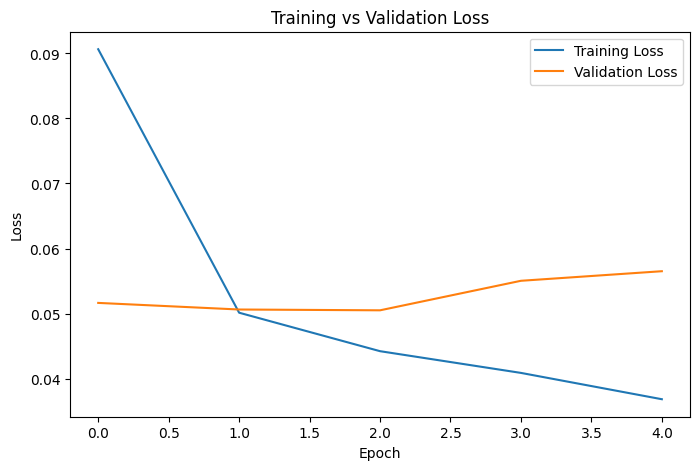

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")

plt.legend()
plt.show()

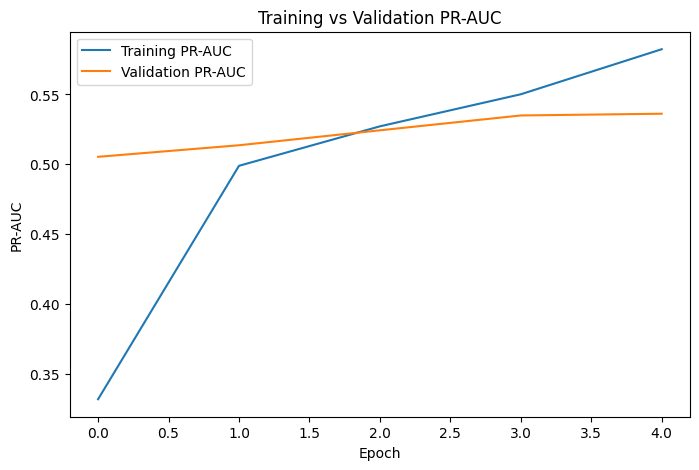

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["pr_auc"], label="Training PR-AUC")
plt.plot(history.history["val_pr_auc"], label="Validation PR-AUC")

plt.xlabel("Epoch")
plt.ylabel("PR-AUC")
plt.title("Training vs Validation PR-AUC")

plt.legend()
plt.show()

In [ ]:
y_val_pred_prob = model.predict(X_val_padded)

print("Prediction shape:", y_val_pred_prob.shape)
print(y_val_pred_prob[:5])

998/998 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step
Prediction shape: (31913, 6)
[[9.99079227e-01 3.98140937e-01 9.81912851e-01 2.26354189e-02
  9.19661045e-01 1.38937160e-01]
 [2.61448440e-04 3.33683281e-09 5.18715888e-06 1.84156505e-07
  2.79778624e-06 2.57388280e-07]
 [7.78264017e-04 4.12652810e-08 2.24403375e-05 1.11031045e-06
  1.47304945e-05 1.56882822e-06]
 [1.05233546e-02 4.32233583e-06 4.77404479e-04 5.92400611e-05
  4.94520762e-04 8.06848475e-05]
 [1.63824612e-03 2.82461230e-07 6.83371254e-05 4.40926306e-06
  4.30506916e-05 6.68638086e-06]]


In [ ]:
#Convert probabilities into predictions

import numpy as np

y_val_pred = (y_val_pred_prob >= 0.5).astype(int)

print("Binary prediction shape:", y_val_pred.shape)

print("First 5 binary predictions:")
print(y_val_pred[:5])

Binary prediction shape: (31913, 6)
First 5 binary predictions:
[[1 0 1 0 1 0]
 [0 0 0 0 0 0]
 [0 0 0 0 0 0]
 [0 0 0 0 0 0]
 [0 0 0 0 0 0]]


In [ ]:
#Calculate evaluation metrics

from sklearn.metrics import classification_report

print(classification_report(
    y_val_array,
    y_val_pred,
    target_names=target_columns,
    zero_division=0
))

               precision    recall  f1-score   support

        toxic       0.78      0.79      0.78      3023
 severe_toxic       0.51      0.22      0.30       309
      obscene       0.83      0.76      0.80      1672
       threat       0.00      0.00      0.00       101
       insult       0.73      0.68      0.70      1570
identity_hate       0.00      0.00      0.00       301

    micro avg       0.77      0.69      0.73      6976
    macro avg       0.47      0.41      0.43      6976
 weighted avg       0.72      0.69      0.70      6976
  samples avg       0.07      0.06      0.06      6976



In [ ]:
print("Actual positive labels:")
print(np.sum(y_val_array, axis=0))

print("\nPredicted positive labels:")
print(np.sum(y_val_pred, axis=0))

print("\nLabel names:")
print(target_columns)

Actual positive labels:
[3023  309 1672  101 1570  301]

Predicted positive labels:
[3054  132 1541    0 1472    0]

Label names:
['toxic', 'severe_toxic', 'obscene', 'threat', 'insult', 'identity_hate']


In [ ]:
#Examine the predicted probabilities

for i, label in enumerate(target_columns):

    print("\nLabel:", label)

    print("Maximum probability:",
          np.max(y_val_pred_prob[:, i]))

    print("Average probability:",
          np.mean(y_val_pred_prob[:, i]))

    print("Number of probabilities >= 0.5:",
          np.sum(y_val_pred_prob[:, i] >= 0.5))


Label: toxic
Maximum probability: 0.9996666
Average probability: 0.10909352
Number of probabilities >= 0.5: 3054

Label: severe_toxic
Maximum probability: 0.6068586
Average probability: 0.011371055
Number of probabilities >= 0.5: 132

Label: obscene
Maximum probability: 0.99110425
Average probability: 0.054149847
Number of probabilities >= 0.5: 1541

Label: threat
Maximum probability: 0.2415105
Average probability: 0.003224784
Number of probabilities >= 0.5: 0

Label: insult
Maximum probability: 0.948389
Average probability: 0.052478373
Number of probabilities >= 0.5: 1472

Label: identity_hate
Maximum probability: 0.38545316
Average probability: 0.008440213
Number of probabilities >= 0.5: 0


In [ ]:
thresholds = [0.1, 0.2, 0.3, 0.4, 0.5]

for i in [3, 5]:

    label = target_columns[i]

    print("\nLabel:", label)

    for threshold in thresholds:

        count = np.sum(
            y_val_pred_prob[:, i] >= threshold
        )

        print(
            "Threshold:", threshold,
            "| Positive predictions:", count
        )


Label: threat
Threshold: 0.1 | Positive predictions: 21
Threshold: 0.2 | Positive predictions: 3
Threshold: 0.3 | Positive predictions: 0
Threshold: 0.4 | Positive predictions: 0
Threshold: 0.5 | Positive predictions: 0

Label: identity_hate
Threshold: 0.1 | Positive predictions: 805
Threshold: 0.2 | Positive predictions: 86
Threshold: 0.3 | Positive predictions: 7
Threshold: 0.4 | Positive predictions: 0
Threshold: 0.5 | Positive predictions: 0


In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.4, 0.5]

for i in [3, 5]:

    label = target_columns[i]

    print("\nLabel:", label)
    print("-" * 55)

    for threshold in thresholds:

        predictions = (
            y_val_pred_prob[:, i] >= threshold
        ).astype(int)

        precision = precision_score(
            y_val_array[:, i], predictions, zero_division=0
        )

        recall = recall_score(
            y_val_array[:, i], predictions, zero_division=0
        )

        f1 = f1_score(
            y_val_array[:, i], predictions, zero_division=0
        )

        print(
            f"Threshold: {threshold:.2f} | "
            f"Precision: {precision:.3f} | "
            f"Recall: {recall:.3f} | "
            f"F1-score: {f1:.3f}"
        )


Label: threat
-------------------------------------------------------
Threshold: 0.05 | Precision: 0.070 | Recall: 0.158 | F1-score: 0.098
Threshold: 0.10 | Precision: 0.048 | Recall: 0.010 | F1-score: 0.016
Threshold: 0.15 | Precision: 0.143 | Recall: 0.010 | F1-score: 0.019
Threshold: 0.20 | Precision: 0.333 | Recall: 0.010 | F1-score: 0.019
Threshold: 0.25 | Precision: 0.000 | Recall: 0.000 | F1-score: 0.000
Threshold: 0.30 | Precision: 0.000 | Recall: 0.000 | F1-score: 0.000
Threshold: 0.40 | Precision: 0.000 | Recall: 0.000 | F1-score: 0.000
Threshold: 0.50 | Precision: 0.000 | Recall: 0.000 | F1-score: 0.000

Label: identity_hate
-------------------------------------------------------
Threshold: 0.05 | Precision: 0.112 | Recall: 0.784 | F1-score: 0.195
Threshold: 0.10 | Precision: 0.170 | Recall: 0.455 | F1-score: 0.248
Threshold: 0.15 | Precision: 0.229 | Recall: 0.219 | F1-score: 0.224
Threshold: 0.20 | Precision: 0.267 | Recall: 0.076 | F1-score: 0.119
Threshold: 0.25 | Preci

In [ ]:
print("Training positive label counts:")

for label in target_columns:
    print(label, ":", y_train[label].sum())

Training positive label counts:
toxic : 12271
severe_toxic : 1286
obscene : 6777
threat : 377
insult : 6307
identity_hate : 1104


In [ ]:
import numpy as np

# Calculate positive and negative counts
positive_counts = np.sum(y_train_array, axis=0)
negative_counts = len(y_train_array) - positive_counts

# Calculate positive class weights
pos_weights = negative_counts / positive_counts

print("Positive counts:", positive_counts)
print("Negative counts:", negative_counts)
print("Positive weights:", pos_weights)

Positive counts: [12271  1286  6777   377  6307  1104]
Negative counts: [115380 126365 120874 127274 121344 126547]
Positive weights: [  9.40265667  98.26205288  17.8359156  337.59681698  19.23957508
 114.6259058 ]


In [ ]:
# Save the baseline LSTM model

model.save("baseline_lstm.keras")

print("Baseline model saved successfully!")

Baseline model saved successfully!


In [ ]:
# Calculate controlled positive weights

pos_weights = np.sqrt(
    negative_counts / positive_counts
)

# Limit maximum weight to 10
pos_weights = np.minimum(pos_weights, 10.0)

print("Controlled positive weights:")

for label, weight in zip(target_columns, pos_weights):
    print(label, ":", round(float(weight), 2))

Controlled positive weights:
toxic : 3.07
severe_toxic : 9.91
obscene : 4.22
threat : 10.0
insult : 4.39
identity_hate : 10.0


In [ ]:
# Build improved LSTM model

improved_model = Sequential([
    Input(shape=(max_len,)),

    Embedding(
        input_dim=vocab_size,
        output_dim=embedding_dim,
        mask_zero=True
    ),

    LSTM(64),

    Dropout(0.3),

    Dense(64, activation="relu"),

    Dropout(0.3),

    Dense(num_labels, activation="sigmoid")
])


# Define weighted binary cross-entropy loss

def weighted_binary_crossentropy(y_true, y_pred):

    epsilon = tf.keras.backend.epsilon()

    y_pred = tf.clip_by_value(
        y_pred,
        epsilon,
        1 - epsilon
    )

    weights = tf.constant(pos_weights, dtype=tf.float32)

    loss = -(
        y_true * tf.math.log(y_pred) * weights
        +
        (1 - y_true) * tf.math.log(1 - y_pred)
    )

    return tf.reduce_mean(loss, axis=-1)


# Compile improved model

improved_model.compile(
    optimizer="adam",
    loss=weighted_binary_crossentropy,
    metrics=[
        tf.keras.metrics.AUC(
            name="pr_auc",
            curve="PR",
            multi_label=True
        )
    ]
)

# Display model summary

improved_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 230, 128)       │     2,560,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,613,958 (9.97 MB)

 Trainable params: 2,613,958 (9.97 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
improved_early_stopping = EarlyStopping(
    monitor="val_pr_auc",
    mode="max",
    patience=2,
    restore_best_weights=True
)

improved_history = improved_model.fit(
    X_train_padded,
    y_train_array,
    validation_data=(
        X_val_padded,
        y_val_array
    ),
    epochs=5,
    batch_size=128,
    callbacks=[improved_early_stopping]
)

Epoch 1/5
998/998 ━━━━━━━━━━━━━━━━━━━━ 21s 20ms/step - loss: 0.1969 - pr_auc: 0.4245 - val_loss: 0.1451 - val_pr_auc: 0.5111
Epoch 2/5
998/998 ━━━━━━━━━━━━━━━━━━━━ 19s 19ms/step - loss: 0.1267 - pr_auc: 0.5102 - val_loss: 0.1340 - val_pr_auc: 0.5303
Epoch 3/5
998/998 ━━━━━━━━━━━━━━━━━━━━ 20s 20ms/step - loss: 0.1098 - pr_auc: 0.5529 - val_loss: 0.1326 - val_pr_auc: 0.5630
Epoch 4/5
998/998 ━━━━━━━━━━━━━━━━━━━━ 19s 19ms/step - loss: 0.0952 - pr_auc: 0.5893 - val_loss: 0.1432 - val_pr_auc: 0.5681
Epoch 5/5
998/998 ━━━━━━━━━━━━━━━━━━━━ 18s 18ms/step - loss: 0.0848 - pr_auc: 0.6228 - val_loss: 0.1586 - val_pr_auc: 0.5717


In [ ]:
improved_val_pred_prob = improved_model.predict(
    X_val_padded
)

print("Improved prediction shape:",
      improved_val_pred_prob.shape)

998/998 ━━━━━━━━━━━━━━━━━━━━ 7s 7ms/step
Improved prediction shape: (31913, 6)


In [ ]:
# Convert improved probabilities into binary predictions

improved_val_pred = (
    improved_val_pred_prob >= 0.5
).astype(int)

print("Improved binary prediction shape:",
      improved_val_pred.shape)

print("\nFirst 5 predictions:")
print(improved_val_pred[:5])

Improved binary prediction shape: (31913, 6)

First 5 predictions:
[[1 1 1 1 1 1]
 [0 0 0 0 0 0]
 [0 0 0 0 0 0]
 [0 0 0 0 0 0]
 [0 0 0 0 0 0]]


In [ ]:
from sklearn.metrics import classification_report

print(classification_report(
    y_val_array,
    improved_val_pred,
    target_names=target_columns,
    zero_division=0
))

               precision    recall  f1-score   support

        toxic       0.67      0.85      0.75      3023
 severe_toxic       0.27      0.94      0.42       309
      obscene       0.70      0.88      0.78      1672
       threat       0.15      0.57      0.24       101
       insult       0.58      0.87      0.69      1570
identity_hate       0.24      0.63      0.35       301

    micro avg       0.57      0.85      0.68      6976
    macro avg       0.44      0.79      0.54      6976
 weighted avg       0.62      0.85      0.71      6976
  samples avg       0.06      0.08      0.06      6976



In [ ]:
print("Actual positive labels:")
print(np.sum(y_val_array, axis=0))

print("\nImproved predicted positive labels:")
print(np.sum(improved_val_pred, axis=0))

print("\nLabel names:")
print(target_columns)

Actual positive labels:
[3023  309 1672  101 1570  301]

Improved predicted positive labels:
[3792 1080 2093  380 2355  779]

Label names:
['toxic', 'severe_toxic', 'obscene', 'threat', 'insult', 'identity_hate']


In [ ]:
from sklearn.metrics import f1_score

thresholds = np.arange(0.10, 0.91, 0.05)

best_thresholds = []

for i, label in enumerate(target_columns):

    best_f1 = 0
    best_threshold = 0.5

    for threshold in thresholds:

        predictions = (
            improved_val_pred_prob[:, i] >= threshold
        ).astype(int)

        score = f1_score(
            y_val_array[:, i],
            predictions,
            zero_division=0
        )

        if score > best_f1:
            best_f1 = score
            best_threshold = threshold

    best_thresholds.append(best_threshold)

    print(
        label,
        "| Best threshold:", round(best_threshold, 2),
        "| Best F1-score:", round(best_f1, 3)
    )

toxic | Best threshold: 0.75 | Best F1-score: 0.782
severe_toxic | Best threshold: 0.8 | Best F1-score: 0.507
obscene | Best threshold: 0.75 | Best F1-score: 0.803
threat | Best threshold: 0.65 | Best F1-score: 0.274
insult | Best threshold: 0.7 | Best F1-score: 0.721
identity_hate | Best threshold: 0.75 | Best F1-score: 0.397


In [ ]:
# Convert probabilities using individual thresholds

best_thresholds = np.array(best_thresholds)

tuned_val_pred = (
    improved_val_pred_prob >= best_thresholds
).astype(int)

print("Tuned prediction shape:", tuned_val_pred.shape)

print("\nTuned classification report:")

from sklearn.metrics import classification_report

print(classification_report(
    y_val_array,
    tuned_val_pred,
    target_names=target_columns,
    zero_division=0
))

Tuned prediction shape: (31913, 6)

Tuned classification report:
               precision    recall  f1-score   support

        toxic       0.81      0.76      0.78      3023
 severe_toxic       0.38      0.77      0.51       309
      obscene       0.81      0.80      0.80      1672
       threat       0.21      0.41      0.27       101
       insult       0.68      0.77      0.72      1570
identity_hate       0.33      0.49      0.40       301

    micro avg       0.70      0.76      0.73      6976
    macro avg       0.54      0.66      0.58      6976
 weighted avg       0.73      0.76      0.74      6976
  samples avg       0.06      0.07      0.06      6976



In [ ]:
# Save our improved model

improved_model.save("toxicity_model.keras")

print("Improved LSTM model saved successfully!")

Improved LSTM model saved successfully!


In [ ]:
import pickle

with open("tokenizer.pkl", "wb") as file:
    pickle.dump(tokenizer, file)

print("Tokenizer saved successfully!")

Tokenizer saved successfully!


In [ ]:
import json

config = {
    "vocab_size": vocab_size,
    "embedding_dim": embedding_dim,
    "max_len": max_len,
    "num_labels": num_labels,
    "target_columns": target_columns,
    "thresholds": best_thresholds.tolist()
}

with open("config.json", "w") as file:
    json.dump(config, file, indent=4)

print("Configuration saved successfully!")

Configuration saved successfully!


In [ ]:
from google.colab import files

files.download("toxicity_model.keras")
files.download("tokenizer.pkl")
files.download("config.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>